# Investigating Structure at Initialisation

We would like to measure the variance of the activation values and back-propagated gradients of a fully connected neural network.

In particular, we would like to investigate how the behaviour of these quantities depends on the choice of the following features.
* The depth $L$ of the neural network
* The width or size of each layer
* The choice of activation function $\sigma$
* The initialisation scheme for the weight $W$ 

### Importing Dependencies

In [1]:
import torch
from torchvision import datasets, transforms
import torch.nn as nn
import torch.nn.functional as F
from neural_network import NeuralNetwork
import matplotlib.pyplot as plt
import numpy as np

### Data Peprocessing

We use the `MNIST` handwritten digits data set to obtain the activations and gradients. For now we only import the training data set as we are not concerned with the testing of the model yet. The training set has 60000 images of 28 x 28 grey-scale images. The 784 pixels will correspond to one neuron in the input layer. Each pixel takes on a value between 0 (white) and 255 (black). The following is the standard way of preparing the data.

In [2]:
# Download and load MNIST training set
mnist = datasets.MNIST("./data", train=True, download=True)

# Create and standardise vector pixel values and labels
x = (mnist.data.float() / 255 - 0.1307) / 0.3081 
y = mnist.targets

### Sample Image from the Data

In [3]:
def show_image(i):
    img = x[i] 
    plt.figure(figsize=(2, 2))               
    plt.imshow(img, cmap="gray")
    plt.axis("off")
    plt.title(f"Label: {y[i].item()}")
    plt.show()

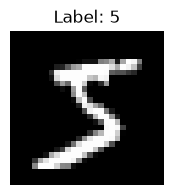

In [4]:
show_image(0)

### Sample usage of the `NeuralNetwork` class

In [5]:
torch.manual_seed(0)                      

# Creating an instance of the neural network
net = NeuralNetwork(
    depth=5, # Will likely be small in our investigation
    width=16, # Multiples of 2 typically
    activation=torch.tanh, # Choose from those built into PyTorch
    weight_init=nn.init.xavier_normal_, # Distribution from which to sample weights
    bias_init=nn.init.zeros_, # Biases set to 0 (typical but not always)
    d_in=784, # Input vector from MNIST
    d_out=10, # Output vector (no. of digits)
)

In [6]:
# Do the first pass of the neural network
net.zero_grad() # Clear old gradients
logits = net(x) # Forward pass

# Back-propagation to obtain gradients
loss = F.cross_entropy(logits, y) # Specify loss function     
loss.backward()     

In [7]:
# Access the activation and gradient values from the results
acts = [h for h in net.h] 
grads = [h.grad for h in net.h] 

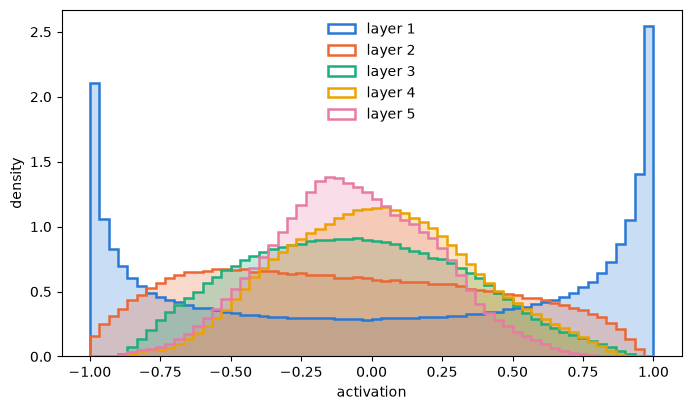

In [8]:
acts = [h for h in net.h]
xs = [a.detach().cpu().flatten().numpy() for a in acts]

colors = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
bins = np.histogram_bin_edges(np.concatenate(xs), bins=60)  # shared edges

fig, ax = plt.subplots(figsize=(8, 4.5))
for i, (x, c) in enumerate(zip(xs, colors)):
    ax.hist(x, bins=bins, density=True, color=c, alpha=0.25, histtype="stepfilled", lw=0)
    ax.hist(x, bins=bins, density=True, color=c, histtype="step", lw=1.8, label=f"layer {i+1}")

ax.set_xlabel("activation")
ax.set_ylabel("density")
ax.legend(frameon=False)
plt.show()